## Actividad 2.2
#### Juan Angel Galvan Navarro 611380

In [ ]:
#Código usado anteriormente para limpieza de datos
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from dbfread import DBF

table = DBF('nacim24.dbf', encoding='latin1')
cols = ['ENT_REGIS', 'MUN_REGIS', 'LOC_REGIS', 'TLOC_REGIS', 'ENT_RESID', 'MUN_RESID', 'LOC_RESID', 'TLOC_RESID', 'ENT_OCURR', 'MUN_OCURR', 'LOC_OCURR', 'TLOC_OCURR', 'SEXO', 'EDAD_REG', 'EDAD_MADN', 'EDAD_PADN', 'DIA_NAC', 'MES_NAC', 'ANO_NAC', 'DIA_REG', 'MES_REG', 'ANO_REG', 'EDAD_MADR', 'EDAD_PADR', 'TIPO_NAC', 'ORDEN_PART', 'LUGAR_PART', 'Q_ATENDIO', 'HIJOS_VIVO', 'HIJOS_SOBR', 'EDOCIV_MAD', 'ESCOL_MAD', 'ESCOL_PAD', 'ACT_MAD', 'ACT_PAD', 'POS_MAD', 'POS_PAD', 'SITLAB_MAD', 'SITLAB_PAD', 'FUE_PRESE', 'HORA_NAC', 'MINUTO_NAC', 'COMPARECIO', 'DIS_RE_OAX']
data = pd.DataFrame([[rec[c] for c in cols] for rec in table], columns=cols)
data = pd.DataFrame([[rec[c] for c in cols] for rec in table], columns=cols)
clean = data[(data.EDAD_MADN != 99) & (data.ESCOL_MAD != 9) &
             (data.EDOCIV_MAD != 9) & (data.ACT_MAD != 9) &
             (data.TLOC_RESID != 99)].copy()
clean = clean.drop(columns=["HIJOS_VIVO"])

## 1. Definición del problema y_test_lda partición de los datos

#### Origen de los datos

Los datos provienen de la base de microdatos **"Estadística de Nacimientos"** publicada por el Instituto Nacional de Estadística y Geografía (INEGI), correspondiente al año 2024. Esta base se conforma a partir de las actas de nacimiento expedidas por el Registro Civil en todo el territorio nacional (incluyendo representaciones consulares para mexicanos en el extranjero), y contiene microdatos a nivel de cada nacimiento registrado, con cobertura geográfica hasta nivel de localidad. Cada fila del archivo `nacim24.dbf` representa un nacimiento registrado, con 44 variables reportadas en el acta o calculadas a partir de ella (INEGI, 2025).

### Variable de salida

Se define la variable categórica `grupo_edad`, con tres clases, a partir de `Edad_madn` (variable continua usada en las actividades previas):

- **Adolescente**: 10 a 19 años
- **Adulta joven**: 20 a 34 años
- **Adulta mayor**: 35 años o más

Los cortes conservan el límite de 19 años ya justificado por la definición de la OMS de embarazo adolescente (Briones Garduño et al., 2024), y_test_lda dividen el resto de la vida reproductiva en dos grupos de tamaño e interés comparables, en vez de tratar "20 años o más" como un solo bloque homogéneo — hay diferencias sociodemográficas relevantes entre una madre de 25 y_test_lda una de 40 años.

### Balance entre clases

In [3]:
from sklearn.model_selection import train_test_split

def clasif(edad):
    if edad <= 19: return "Adolescente"
    elif edad <= 34: return "Adulta joven"
    else: return "Adulta mayor"

clean["grupo_edad"] = clean.EDAD_MADN.apply(clasif)

train, test = train_test_split(
    clean, test_size=0.2, stratify=clean["grupo_edad"], random_state=10
)

tabla_1_1 = clean.grupo_edad.value_counts().to_frame("Observaciones")
tabla_1_1["%"] = (clean.grupo_edad.value_counts(normalize=True) * 100).round(2)
tabla_1_1.index.name = "Clase"

print("Tabla 1.1 — Distribución de la variable grupo_edad")
print(tabla_1_1)

tabla_1_1 = clean.grupo_edad.value_counts().to_frame("Observaciones")
tabla_1_1["%"] = (clean.grupo_edad.value_counts(normalize=True) * 100).round(2)
tabla_1_1.index.name = "Clase"

print("Tabla 1.1 — Distribución de la variable grupo_edad")
print(tabla_1_1)

Tabla 1.1 — Distribución de la variable grupo_edad
              Observaciones      %
Clase                             
Adulta joven         872478  72.92
Adolescente          168065  14.05
Adulta mayor         156022  13.04
Tabla 1.1 — Distribución de la variable grupo_edad
              Observaciones      %
Clase                             
Adulta joven         872478  72.92
Adolescente          168065  14.05
Adulta mayor         156022  13.04


La variable está desbalanceada: casi tres de cada cuatro nacimientos corresponden a "adulta joven", mientras que "adolescente" y_test_lda "adulta mayor" son minoritarias y_test_lda de tamaño similar entre sí (~14% y_test_lda ~13%). Este desbalance es un reflejo genuino del patrón real de fecundidad por edad en México, no un artefacto de los datos, pero debe tenerse presente al interpretar cualquier métrica de exactitud global más adelante.

### Partición de los datos

Se divide el conjunto en 80% entrenamiento / 20% prueba, de forma **estratificada** por `grupo_edad`, para que la proporción de las tres clases se conserve igual en ambos subconjuntos. Esto es importante porque, si por azar una de las clases minoritarias quedara sub-representada en el conjunto de prueba, las métricas calculadas ahí (sensibilidad por clase, matriz de confusión) serían poco confiables al estar basadas en muy pocas observaciones — un desbalance adicional introducido por la partición, encima del desbalance natural que ya existe.

In [ ]:
from sklearn.model_selection import train_test_split

def clasif(edad):
    if edad <= 19: return "Adolescente"
    elif edad <= 34: return "Adulta joven"
    else: return "Adulta mayor"

clean["grupo_edad"] = clean.EDAD_MADN.apply(clasif)

train, test = train_test_split(
    clean, test_size=0.2, stratify=clean["grupo_edad"], random_state=10
)

## 2. Modelo basado en LDA

### Selección de variables coherentes con los supuestos de LDA

LDA asume que cada clase sigue una distribución normal multivariada, con la misma matriz de covarianza entre clases (homoscedasticidad). Esto excluye de forma natural a las variables binarias/dummy del proyecto anterior (`Act_mad`, `edociv_2`): una variable de solo dos valores no puede aproximar una distribución normal bajo ningún supuesto razonable.

Se seleccionan únicamente `Escol_mad` y_test_lda `Orden_part`, las dos variables cuantitativas disponibles con suficientes niveles distintos para tratarse como aproximadamente continuas, coherentes con el supuesto de normalidad que exige el modelo (aun siendo variables discretas/ordinales, son la mejor aproximación disponible en este dataset — no hay variables verdaderamente continuas).

In [44]:
vars_lda = ["ESCOL_MAD", "ORDEN_PART"]
X_train_lda = train[vars_lda].values.astype(float)  
y_train_lda = train["grupo_edad"].values              
clases = np.unique(y_train_lda)

medias = X_train_lda.mean(axis=0); stds = X_train_lda.std(axis=0)
Xs = (X_train_lda - medias) / stds
media_global = Xs.mean(axis=0)

Sw = np.zeros((2,2)); Sb = np.zeros((2,2))
mu, pi = {}, {}
for c in clases:
    Xc = Xs[y_train_lda==c]; nc = len(Xc); mc = Xc.mean(axis=0)
    mu[c] = mc; pi[c] = nc/len(Xs)
    diff = Xc - mc
    Sw += diff.T @ diff
    d = (mc - media_global).reshape(-1,1)
    Sb += nc * (d @ d.T)

Sigma = Sw / (len(Xs) - len(clases))
Sigma_inv = np.linalg.inv(Sigma)

eigvals, eigvecs = np.linalg.eig(np.linalg.inv(Sw) @ Sb)
orden = np.argsort(eigvals)[::-1]
eigvals = eigvals[orden].real
eigvecs = eigvecs[:,orden].real
LD = Xs @ eigvecs

def clasificar_lda(X):
    scores = np.zeros((len(X), len(clases)))
    for i, c in enumerate(clases):
        m = mu[c]
        scores[:, i] = X @ Sigma_inv @ m - 0.5 * m @ Sigma_inv @ m + np.log(pi[c])
    return clases[np.argmax(scores, axis=1)]

# Conjunto de prueba real para LDA (esto faltaba por completo)
X_test_lda = test[vars_lda].values.astype(float)
y_test_lda = test["grupo_edad"].values
Xs_test = (X_test_lda - medias) / stds
pred_lda_test = clasificar_lda(Xs_test)

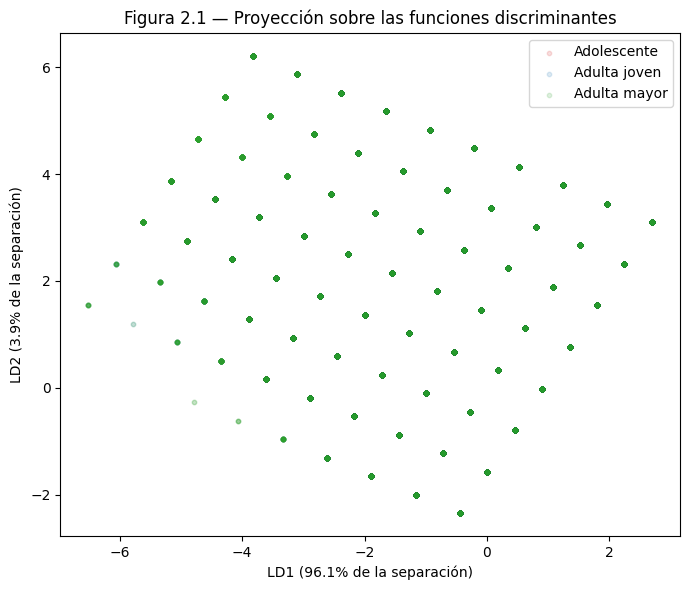

In [46]:
import matplotlib.pyplot as plt

colores = {"Adolescente": "#d62728", "Adulta joven": "#1f77b4", "Adulta mayor": "#2ca02c"}

plt.figure(figsize=(7, 6))
for c in clases:
    mask = y_train_lda == c   
    plt.scatter(LD[mask, 0], LD[mask, 1], alpha=0.15, s=10, color=colores[c], label=c)

plt.xlabel(f"LD1 ({eigvals[0]/eigvals.sum()*100:.1f}% de la separación)")
plt.ylabel(f"LD2 ({eigvals[1]/eigvals.sum()*100:.1f}% de la separación)")
plt.title("Figura 2.1 — Proyección sobre las funciones discriminantes")
plt.legend()
plt.tight_layout()
plt.show()

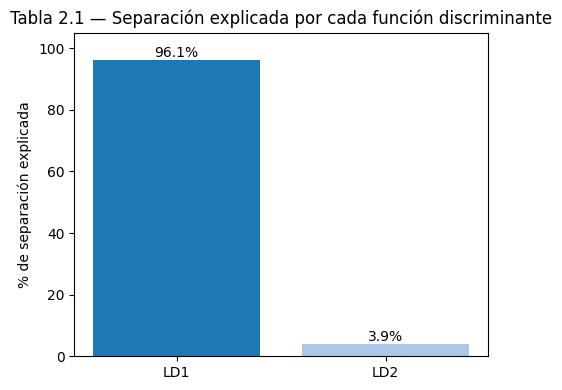

In [27]:
tabla_2_1 = pd.DataFrame({
    "Eigenvalor": eigvals,
    "% de separación explicada": eigvals / eigvals.sum() * 100
}, index=["LD1", "LD2"])

plt.figure(figsize=(5, 4))
plt.bar(tabla_2_1.index, tabla_2_1["% de separación explicada"], color=["#1f77b4", "#aec7e8"])
plt.ylabel("% de separación explicada")
plt.title("Tabla 2.1 — Separación explicada por cada función discriminante")
for i, v in enumerate(tabla_2_1["% de separación explicada"]):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center")
plt.ylim(0, 105)
plt.tight_layout()
plt.show()

### Separación observada y_test_lda adecuación de la frontera lineal

**LD1 concentra el 96.1% de la separación entre clases; LD2 solo el 3.9%** (Tabla 2.1) — prácticamente toda la información discriminante entre las tres clases vive en una sola dirección lineal, y_test_lda agregar la segunda función discriminante aporta muy poco.

La Figura 2.1 muestra la proyección de una muestra de observaciones sobre ambas funciones. Se observa una separación clara pero **parcial**: "Adulta mayor" se agrupa consistentemente hacia valores negativos de LD1, "Adolescente" hacia valores positivos, y_test_lda "Adulta joven" ocupa la región central, traslapándose visiblemente con ambos extremos. No hay una frontera limpia entre clases — hay bandas de transición amplias, especialmente entre "Adulta joven" y_test_lda las otras dos.

Esto es consistente con la naturaleza de las variables usadas: `Orden_part` y_test_lda `Escol_mad` son discretas, con pocos valores posibles, lo que produce agrupaciones en "columnas" superpuestas sobre la proyección (visible como puntos repetidos en la misma posición) en vez de una nube continua. Una frontera **lineal** parece razonable como primera aproximación —hay una tendencia clara y_test_lda monótona—, pero el traslape sustancial entre clases sugiere que el modelo tendrá dificultad para distinguir con precisión, particularmente a la clase "Adulta joven" de sus vecinas. Esto se confirmará (o no) al revisar las métricas de desempeño más adelante.

## 3. Modelo basado en árboles de decisión

### Variables utilizadas

A diferencia de LDA, un árbol no asume normalidad ni homoscedasticidad, por lo que puede incorporar variables cualitativas sin restricción. Se utiliza el conjunto completo disponible: `Escol_mad`, `Act_mad`, `Orden_part`, `Tloc_resid` (numéricas/ordinales) más las variables dummy de `Edociv_mad` y_test_lda `Ent_resid` (40 variables candidatas en total) — el árbol mismo se encarga de descartar las que no aportan, a diferencia de LDA donde la selección de variables coherentes había que hacerla de antemano.

### Parámetros principales seleccionados

- **Criterio de división:** Gini (default de `sklearn`), que mide la impureza de cada nodo — es el criterio estándar cubierto en clase y_test_lda computacionalmente más rápido que entropía, sin diferencia práctica relevante en la mayoría de los casos.
- **Métrica de selección del árbol podado:** *balanced accuracy* (exactitud balanceada, el promedio de la sensibilidad por clase) en vez de exactitud simple, dado el desbalance ya documentado entre las tres clases (72.9% / 14.1% / 13.0%) — la misma razón por la que en la actividad de regresión logística se prefirieron sensibilidad/especificidad sobre exactitud sola.

In [35]:
clean["ACT_MAD"] = clean["ACT_MAD"].map({1: 1, 2: 0})
clean = pd.get_dummies(clean, columns=["EDOCIV_MAD"], prefix="edociv", drop_first=True)
clean = pd.get_dummies(clean, columns=["ENT_RESID"], prefix="ent", drop_first=True)

In [36]:
from sklearn.tree import DecisionTreeClassifier
np.random.seed(10)

train, test = train_test_split(clean, test_size=0.2, stratify=clean["grupo_edad"], random_state=10)

cols_num = ["ESCOL_MAD", "ACT_MAD", "ORDEN_PART", "TLOC_RESID"]
cols_dummy = [c for c in clean.columns if c.startswith("edociv_") or c.startswith("ent_")]
feature_cols = cols_num + cols_dummy

X_train = train[feature_cols].astype(float).values
y_train = train["grupo_edad"].values
X_test = test[feature_cols].astype(float).values
y_test = test["grupo_edad"].values
idx_muestra = np.random.choice(len(X_train), 100000, replace=False)
X_train_muestra = X_train[idx_muestra]
y_train_muestra = y_train[idx_muestra]
arbol_completo = DecisionTreeClassifier(random_state=10)
path = arbol_completo.cost_complexity_pruning_path(X_train_muestra, y_train_muestra)
ccp_alphas = np.unique(path.ccp_alphas)
ccp_alphas = np.clip(ccp_alphas, 0, None)  # corrige alpha negativo por error numérico de punto flotante

print("Tabla 3.1 — Cantidad de valores alpha candidatos:", len(ccp_alphas))
print("Rango de alpha:", ccp_alphas.min(), "-", ccp_alphas.max())

Tabla 3.1 — Cantidad de valores alpha candidatos: 5211
Rango de alpha: 0.0 - 0.021625434986318914


### Poda del árbol (cost complexity pruning)

Un árbol sin restricciones (`ccp_alpha=0`) se ajusta perfectamente al ruido de entrenamiento (miles de hojas), lo cual genera sobreajuste y_test_lda un árbol imposible de interpretar. El *cost complexity pruning* agrega una penalización por cada hoja adicional del árbol, controlada por α: mientras más grande α, más se penaliza la complejidad y_test_lda más pequeño (podado) resulta el árbol.

Para elegir α, se evalúan 30 valores en escala logarítmica mediante validación cruzada de 5 folds (sobre una muestra de 100,000 filas de entrenamiento, por costo computacional), midiendo la *balanced accuracy* promedio en cada caso.

In [37]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import balanced_accuracy_score

alphas = np.logspace(np.log10(1e-6), np.log10(0.02), 30)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=10)

resultados = []
for a in alphas:
    scores = []
    for fit_idx, val_idx in skf.split(X_train_muestra, y_train_muestra):
        arbol = DecisionTreeClassifier(random_state=10, ccp_alpha=a)
        arbol.fit(X_train_muestra[fit_idx], y_train_muestra[fit_idx])
        pred = arbol.predict(X_train_muestra[val_idx])
        scores.append(balanced_accuracy_score(y_train_muestra[val_idx], pred))
    resultados.append((a, np.mean(scores), np.std(scores), arbol.get_n_leaves()))

tabla_3_2 = pd.DataFrame(resultados, columns=["alpha", "balanced_acc_media", "std", "n_hojas"])
print("Tabla 3.2 — Balanced accuracy por valor de alpha")
print(tabla_3_2)

Tabla 3.2 — Balanced accuracy por valor de alpha
       alpha  balanced_acc_media       std  n_hojas
0   0.000001            0.479608  0.005092    11976
1   0.000001            0.479380  0.005161    11432
2   0.000002            0.479100  0.005125    10817
3   0.000003            0.478136  0.004978     9834
4   0.000004            0.478482  0.005488     8608
5   0.000006            0.479192  0.006131     7101
6   0.000008            0.480022  0.004842     5234
7   0.000011            0.479977  0.004815     2861
8   0.000015            0.481185  0.007656     1308
9   0.000022            0.479629  0.003409      448
10  0.000030            0.479533  0.006215      161
11  0.000043            0.481745  0.006057       79
12  0.000060            0.483565  0.006507       58
13  0.000085            0.482529  0.012560       39
14  0.000119            0.488062  0.003960       33
15  0.000168            0.478266  0.014469       29
16  0.000236            0.484673  0.002775       22
17  0.000332   

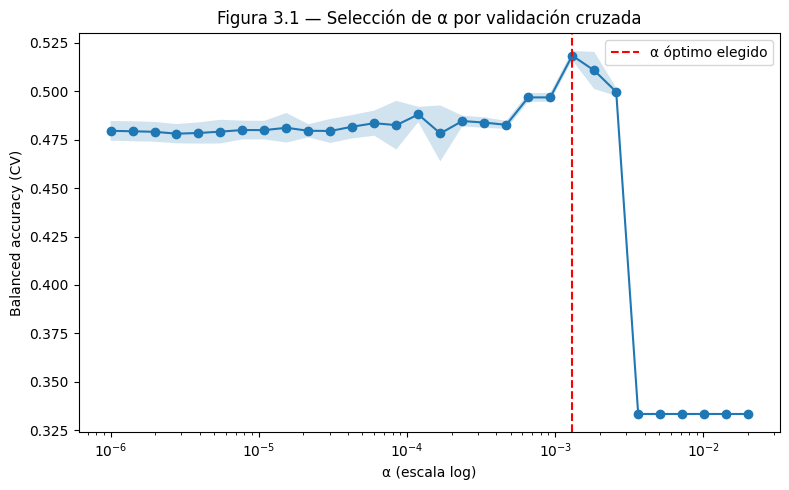

In [38]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(tabla_3_2.alpha, tabla_3_2.balanced_acc_media, marker="o", color="#1f77b4")
ax1.fill_between(tabla_3_2.alpha,
                  tabla_3_2.balanced_acc_media - tabla_3_2["std"],
                  tabla_3_2.balanced_acc_media + tabla_3_2["std"], alpha=0.2)
ax1.set_xscale("log")
ax1.set_xlabel("α (escala log)")
ax1.set_ylabel("Balanced accuracy (CV)")
ax1.axvline(0.001302, color="red", linestyle="--", label="α óptimo elegido")
ax1.legend()
ax1.set_title("Figura 3.1 — Selección de α por validación cruzada")
plt.tight_layout()
plt.show()

La *balanced accuracy* se mantiene relativamente plana (~0.48) para valores pequeños de α —árboles grandes, con miles de hojas, que sobreajustan sin ganar generalización—, mejora notablemente hasta un máximo de **0.5185 en α ≈ 0.0013** (árbol de solo 8 hojas), y_test_lda luego colapsa abruptamente a 0.333 (equivalente a una sola clase) para α mayor a 0.0036, punto en el que la poda es tan agresiva que el árbol deja de dividir el espacio de forma útil. **Se elige α = 0.0013**: es el punto de mejor desempeño con la menor complejidad posible antes de la caída — más allá de este punto no hay ganancia, y_test_lda un árbol de solo 8 hojas es, además, mucho más interpretable que uno con cientos.

### Árbol final

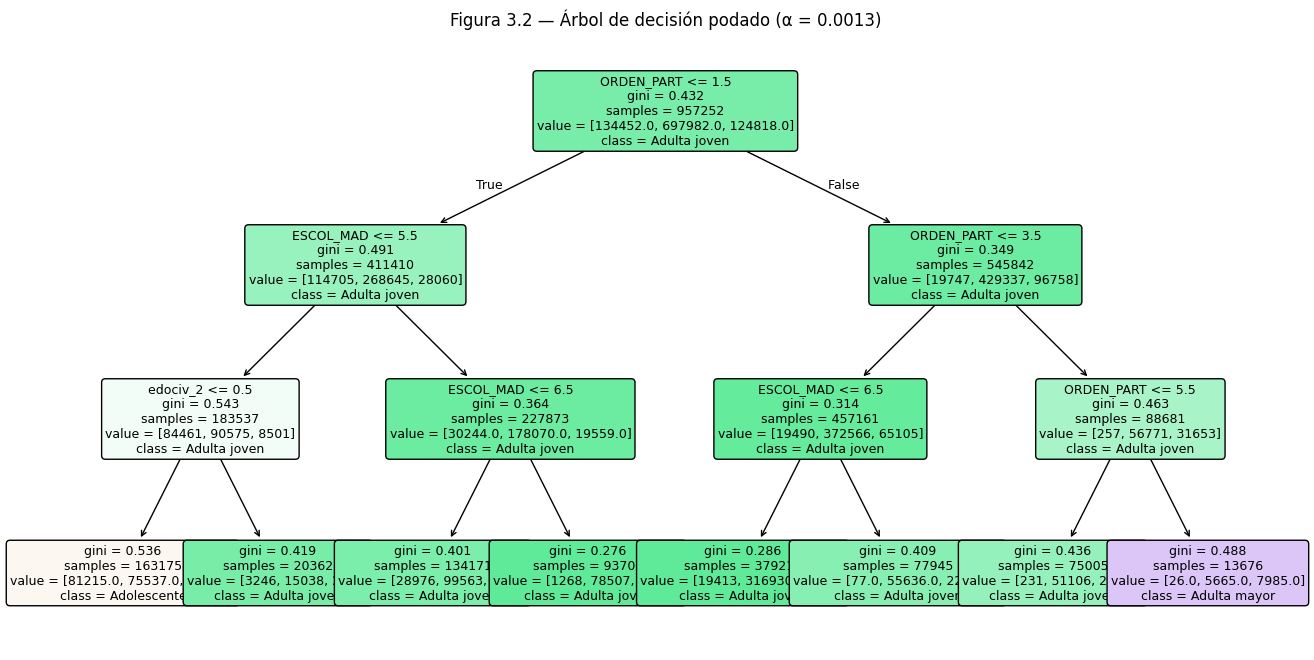

In [39]:
from sklearn.tree import plot_tree

arbol_final = DecisionTreeClassifier(random_state=10, ccp_alpha=0.001302)
arbol_final.fit(X_train, y_train)

plt.figure(figsize=(16, 8))
plot_tree(arbol_final, feature_names=feature_cols, class_names=arbol_final.classes_,
          filled=True, rounded=True, fontsize=9)
plt.title("Figura 3.2 — Árbol de decisión podado (α = 0.0013)")
plt.show()

### Interpretación de las reglas y_test_lda relevancia de variables

El árbol final tiene solo 8 hojas y_test_lda profundidad 3, y_test_lda de las 40 variables candidatas usa únicamente tres: `Orden_part`, `Escol_mad` y_test_lda `edociv_2` — las mismas tres variables que ya resultaron relevantes en los modelos de regresión de las actividades anteriores. Ninguna de las 31 dummies de entidad ni `Act_mad`/`Tloc_resid` se usó en ninguna división.

Reglas principales:
- `Orden_part > 5.5` → **Adulta mayor** (un sexto hijo o más prácticamente garantiza que la madre ya no es adolescente ni joven).
- `Orden_part ≤ 1.5` (primer hijo) y_test_lda `Escol_mad ≤ 5.5` y_test_lda `edociv_2 ≤ 0.5` (no casada) → **Adolescente**: el único camino del árbol que predice esta clase, combina primer parto, baja escolaridad y_test_lda estado civil distinto a casada.
- El resto de las combinaciones (primer parto con escolaridad más alta o siendo casada, o partos de orden intermedio) caen en **Adulta joven**, la clase mayoritaria — consistente con que 73% de los datos pertenecen a esta clase.

Esto confirma la relevancia de `Orden_part` y_test_lda `Escol_mad` ya observada en LDA (eran las únicas dos variables usadas ahí también), y_test_lda añade a `edociv_2` como la variable que permite distinguir específicamente a las adolescentes, algo que las funciones discriminantes de LDA no exponían de forma tan directa.

In [40]:
tabla_3_3 = pd.Series(arbol_final.feature_importances_, index=feature_cols).sort_values(ascending=False)
tabla_3_3 = tabla_3_3[tabla_3_3 > 0]

print("Tabla 3.3 — Importancia de variables en el árbol final")
print(tabla_3_3)

Tabla 3.3 — Importancia de variables en el árbol final
ORDEN_PART    0.489656
ESCOL_MAD     0.449362
edociv_2      0.060982
dtype: float64


In [41]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix

def metricas_por_clase(cm, clases):
    resultados = {}
    total = cm.sum()
    for i, c in enumerate(clases):
        TP = cm[i, i]
        FN = cm[i, :].sum() - TP
        FP = cm[:, i].sum() - TP
        TN = total - TP - FN - FP
        resultados[c] = (TP/(TP+FN), TN/(TN+FP))   # (sensibilidad, especificidad)
    return resultados

clases = np.unique(y_test)

pred_tree_test = arbol_final.predict(X_test)  

cm_lda = confusion_matrix(y_test_lda, pred_lda_test, labels=clases)
acc_lda = accuracy_score(y_test_lda, pred_lda_test)
bacc_lda = balanced_accuracy_score(y_test_lda, pred_lda_test)
met_lda = metricas_por_clase(cm_lda, clases)

cm_tree = confusion_matrix(y_test, pred_tree_test, labels=clases)
acc_tree = accuracy_score(y_test, pred_tree_test)
bacc_tree = balanced_accuracy_score(y_test, pred_tree_test)
met_tree = metricas_por_clase(cm_tree, clases)

tabla_4_1 = pd.DataFrame({
    "LDA - sensibilidad": {c: met_lda[c][0] for c in clases},
    "LDA - especificidad": {c: met_lda[c][1] for c in clases},
    "Árbol - sensibilidad": {c: met_tree[c][0] for c in clases},
    "Árbol - especificidad": {c: met_tree[c][1] for c in clases},
}).round(4)

print("Tabla 4.1 — Sensibilidad y_test_lda especificidad por clase, LDA vs Árbol")
print(tabla_4_1)
print()
print(f"Accuracy       -> LDA: {acc_lda:.4f}   Árbol: {acc_tree:.4f}")
print(f"Balanced acc.  -> LDA: {bacc_lda:.4f}   Árbol: {bacc_tree:.4f}")

Tabla 4.1 — Sensibilidad y_test_lda especificidad por clase, LDA vs Árbol
              LDA - sensibilidad  LDA - especificidad  Árbol - sensibilidad  \
Adolescente               0.0430               0.9839                0.6046   
Adulta joven              0.9665               0.0794                0.8825   
Adulta mayor              0.1004               0.9851                0.0658   

              Árbol - especificidad  
Adolescente                  0.8996  
Adulta joven                 0.3698  
Adulta mayor                 0.9931  

Accuracy       -> LDA: 0.7239   Árbol: 0.7370
Balanced acc.  -> LDA: 0.3700   Árbol: 0.5176


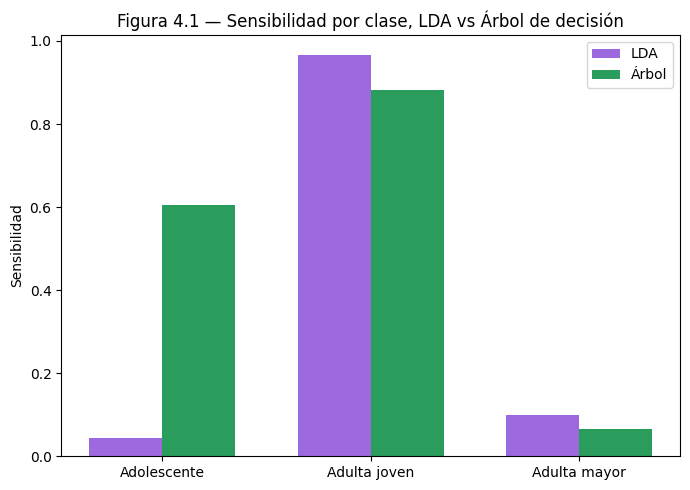

In [42]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(clases))
ancho = 0.35

plt.figure(figsize=(7, 5))
plt.bar(x - ancho/2, tabla_4_1["LDA - sensibilidad"], width=ancho, label="LDA", color="#9c6ade")
plt.bar(x + ancho/2, tabla_4_1["Árbol - sensibilidad"], width=ancho, label="Árbol", color="#2a9d5c")
plt.xticks(x, clases)
plt.ylabel("Sensibilidad")
plt.title("Figura 4.1 — Sensibilidad por clase, LDA vs Árbol de decisión")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Evaluación y comparación de los modelos

### Comparación cuantitativa

La exactitud global es prácticamente igual entre ambos modelos (72.4% LDA vs. 73.7% árbol) — si solo se mirara esta métrica, parecerían equivalentes. Pero la *balanced accuracy* los separa claramente: 0.370 en LDA contra 0.518 en el árbol. LDA detecta casi perfectamente a "Adulta joven" (96.65% de sensibilidad) pero falla dramáticamente con las otras dos clases (4.3% y 10.0%) — en la práctica, se comporta casi como si solo supiera predecir la clase mayoritaria. El árbol distribuye su capacidad de forma mucho más pareja (60.5%, 88.3%, 6.6%).

### Coherencia entre visualizaciones y métricas

Esto es consistente con la Figura 2.1: la proyección de LDA mostraba a "Adulta joven" ocupando la región central, traslapada con las otras dos clases en sus extremos, sin frontera limpia. Una frontera lineal no logra aislar "Adolescente" y "Adulta mayor" de esa región compartida, y el resultado práctico es que LDA termina clasificando casi todo como "Adulta joven".

### Influencia de los supuestos del modelo

LDA asume normalidad multivariada y una misma matriz de covarianza para las tres clases. Ninguno de los dos supuestos se sostiene bien aquí: `Escol_mad` y `Orden_part` son discretas con pocos valores (no continuas ni normales), y las tres clases tienen tamaños muy distintos (73%/14%/13%) con estructuras de dispersión probablemente distintas — forzar una covarianza compartida distorsiona la frontera a favor de la clase mayoritaria. El árbol no depende de ningún supuesto distribucional, por lo que no se ve penalizado de la misma forma.

### Ventajas y limitaciones

- **LDA**: rápido e interpretable geométricamente, pero limitado a 2 variables por la restricción de normalidad, y sus supuestos no encajan bien con estos datos.
- **Árbol**: sin restricciones distribucionales, usa variables cualitativas directamente y encuentra una regla explícita (primer parto + baja escolaridad + no casada → adolescente), a costa de mayor volatilidad ante cambios en los datos, mitigada aquí por la poda.

### Conclusión

Se considera que el **árbol de decisión es el modelo más adecuado** para esta tarea. La evidencia cuantitativa (balanced accuracy 0.518 vs. 0.370, sensibilidad mucho más pareja entre clases) y cualitativa (los supuestos de LDA no encajan con variables discretas, no normales y clases de tamaño muy dispar) apuntan en la misma dirección, aun reconociendo que el desempeño del árbol para "Adulta mayor" sigue siendo débil.

### Doy mi palabra que he realizado esta actividad con integridad academica.
### Referencias bibliograficas
- World Health Organization: WHO. (2024, April 10). Adolescent pregnancy. Translate.Goog; World Health Organization: WHO. https://www.who.int/news-room/fact-sheets/detail/adolescent-pregnancy
- Instituto Nacional de Estadística y Geografía. (2025). Estadística de Nacimientos Registrados 2024 [Conjunto de microdatos]. INEGI. https://www.inegi.org.mx/programas/natalidad/ 
- Instituto Nacional de Estadística y Geografía. (2025). Estadística de nacimientos: Descripción de la base de datos nacional. INEGI.

*Nota: Se uso IAG para la generación de código nuevo, y_test_lda para la redacción correcta de los análisis.*
